In [2]:
import torch
import matplotlib.pyplot as plt
from torch_geometric.datasets import TUDataset

c:\Users\pablo\Desktop\UPF\Thesis\02_enzymes_classifier\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [3]:
dataset = TUDataset(
    root="../data",
    name="ENZYMES",
    use_node_attr=True
)

print(dataset)
print(f"Graphs: {len(dataset)}")
print(f"Classes: {dataset.num_classes}")
print(f"Features per node: {dataset.num_node_features}")
print(f"Features per edge: {dataset.num_edge_features}")

Processing...


ENZYMES(600)
Graphs: 600
Classes: 6
Features per node: 21
Features per edge: 0


Done!


In [4]:
graph = dataset[0]

print(graph)
print(f"Nodes: {graph.num_nodes}")
print(f"Edge entries: {graph.num_edges}")
print(f"Undirected: {graph.is_undirected()}")
print(f"Graph class: {graph.y.item()}")

print("\nFirst node's features:")
print(graph.x[0])

print(f"\nLabels shape: {graph.y.shape}")

Data(edge_index=[2, 168], x=[37, 21], y=[1])
Nodes: 37
Edge entries: 168
Undirected: True
Graph class: 5

First node's features:
tensor([11.0000, 15.8870, 37.7800, -0.5100,  1.7010, 93.9000,  4.0000,  5.0000,
         2.0000,  4.0000,  4.0000,  3.0000,  3.0000,  4.0000,  4.0000,  3.0000,
         6.0000,  2.0000,  1.0000,  0.0000,  0.0000])

Labels shape: torch.Size([1])


Average nodes per graph: 32.6
Smallest graph: 2 nodes
Largest graph: 126 nodes
Graphs per class: [100, 100, 100, 100, 100, 100]


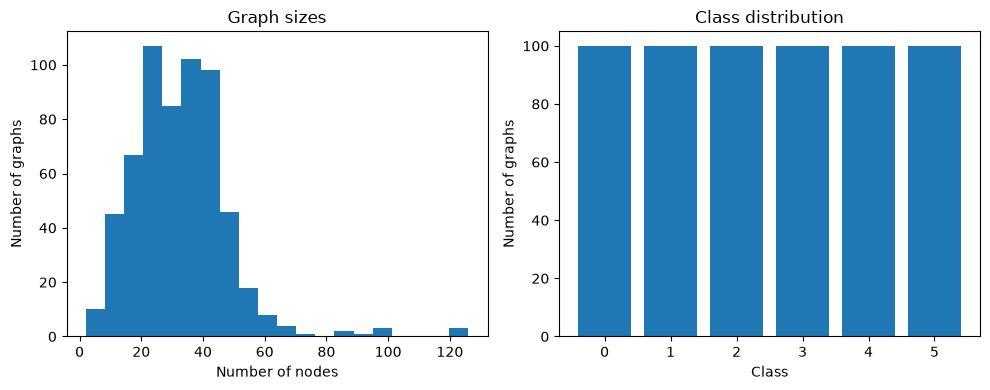

In [5]:
node_counts = torch.tensor([g.num_nodes for g in dataset])
labels = torch.cat([g.y for g in dataset])
class_counts = torch.bincount(labels, minlength=dataset.num_classes)

print(f"Average nodes per graph: {node_counts.float().mean():.1f}")
print(f"Smallest graph: {node_counts.min().item()} nodes")
print(f"Largest graph: {node_counts.max().item()} nodes")
print(f"Graphs per class: {class_counts.tolist()}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(node_counts.numpy(), bins=20)
axes[0].set_title("Graph sizes")
axes[0].set_xlabel("Number of nodes")
axes[0].set_ylabel("Number of graphs")

axes[1].bar(range(dataset.num_classes), class_counts.numpy())
axes[1].set_title("Class distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of graphs")

plt.tight_layout()
plt.show()